# 02 — Sensör Modelleri

Amaç: sensör okumalarından yangın tahmini yapan modelleri karşılaştırmak, en iyisini seçmek ve test setinde **bir kez** ölçmek.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../smoke_detection_iot.csv")  # CSV proje klasöründe (GitHub'a gitmez)

# Veri 5 ayrı kayıt oturumundan oluşuyor: CNT sayacı her yeni oturumda sıfırdan başlıyor.
# CNT bir önceki satırdan küçükse yeni oturum başlamış demektir.
df["oturum"] = (df["CNT"].diff() < 0).cumsum()
# Her satırın kendi oturumu içindeki konumu (0 = oturumun başı, 1'e yakın = sonu)
df["sira"] = df.groupby("oturum").cumcount()
df["oran"] = df["sira"] / df.groupby("oturum")["CNT"].transform("size")

print(df.groupby("oturum")["Fire Alarm"].agg(["size", "mean"]))

df = df.drop(columns=["Unnamed: 0", "UTC", "CNT"])

         size      mean
oturum                 
0       24994  0.872849
1       24994  0.872849
2        1154  0.971404
3        5744  0.000348
4        5744  0.000348


## Veriyi bölme

Veri seti tek bir zaman akışı değil; art arda eklenmiş 5 kayıt oturumundan oluşuyor (yukarıdaki tablo). Dosyayı düz %60/%20/%20 bölersek test setine neredeyse yalnızca yangınsız oturumlar düşer. Bu yüzden **her oturumu kendi içinde zamana göre** bölüyoruz: ilk %60 eğitim, sonraki %20 doğrulama, son %20 test. Rastgele bölme yapmıyoruz çünkü arka arkaya satırlar birbirinin neredeyse kopyası.

In [2]:
# Her oturumu KENDİ İÇİNDE zamana göre böl: ilk %60 eğitim, sonraki %20 doğrulama, son %20 test
egitim = df[df["oran"] < 0.6]
dogrulama = df[(df["oran"] >= 0.6) & (df["oran"] < 0.8)]
test = df[df["oran"] >= 0.8]

# Yardımcı sütunlar modele GİRMEZ (sıra bilgisi sızdırır)
yardimci = ["Fire Alarm", "oturum", "sira", "oran"]
X_egitim = egitim.drop(columns=yardimci)
y_egitim = egitim["Fire Alarm"]
X_dogrulama = dogrulama.drop(columns=yardimci)
y_dogrulama = dogrulama["Fire Alarm"]
X_test = test.drop(columns=yardimci)
y_test = test["Fire Alarm"]

print("Eğitim:", X_egitim.shape, "yangın oranı:", round(y_egitim.mean(), 3))
print("Doğrulama:", X_dogrulama.shape, "yangın oranı:", round(y_dogrulama.mean(), 3))
print("Test:", X_test.shape, "yangın oranı:", round(y_test.mean(), 3))

Eğitim: (37581, 12) yangın oranı: 0.647
Doğrulama: (12527, 12) yangın oranı: 0.817
Test: (12522, 12) yangın oranı: 0.817


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# StandardScaler: her sensörü aynı ölçeğe getirir, sonra modele verir
model_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model_lr.fit(X_egitim, y_egitim)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Temperature[C]','Humidity[%]','TVOC[ppb]',...,'NC0.5','NC1.0','NC2.5']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [4]:
from sklearn.tree import DecisionTreeClassifier
model_agac = DecisionTreeClassifier(max_depth=8, random_state=42)
model_agac.fit(X_egitim, y_egitim)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tahmin_lr = model_lr.predict(X_dogrulama)
print("Lojistik Regresyon:")
print("  Accuracy:", accuracy_score(y_dogrulama, tahmin_lr))
print("  Precision:", precision_score(y_dogrulama, tahmin_lr))
print("  Recall:", recall_score(y_dogrulama, tahmin_lr))
print("  F1:", f1_score(y_dogrulama, tahmin_lr))

tahmin_agac = model_agac.predict(X_dogrulama)
print("\nKarar Ağacı:")
print("  Accuracy:", accuracy_score(y_dogrulama, tahmin_agac))
print("  Precision:", precision_score(y_dogrulama, tahmin_agac))
print("  Recall:", recall_score(y_dogrulama, tahmin_agac))
print("  F1:", f1_score(y_dogrulama, tahmin_agac))

Lojistik Regresyon:
  Accuracy: 0.8223038237407201
  Precision: 0.8215864341396769
  Recall: 0.9994134323980839
  F1: 0.9018172194777699

Karar Ağacı:
  Accuracy: 0.8996567414384928
  Precision: 0.8911754447157307
  Recall: 0.9991201485971258
  F1: 0.9420657233718948


Recall (duyarlılık) bizim için en kritik metrik çünkü yangını kaçırmak, yanlış alarm vermekten çok daha tehlikelidir. Bu yüzden model seçiminde recall >= 0.95 şartı aranacaktır.

In [6]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_egitim, y_egitim)

tahmin_rf = model_rf.predict(X_dogrulama)
print("Random Forest:")
print("  Accuracy:", accuracy_score(y_dogrulama, tahmin_rf))
print("  Precision:", precision_score(y_dogrulama, tahmin_rf))
print("  Recall:", recall_score(y_dogrulama, tahmin_rf))
print("  F1:", f1_score(y_dogrulama, tahmin_rf))

Random Forest:
  Accuracy: 0.903967430350443
  Precision: 0.8947690692792163
  Recall: 1.0
  F1: 0.9444623978579013


In [7]:
from sklearn.neural_network import MLPClassifier

model_mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42))
model_mlp.fit(X_egitim, y_egitim)

tahmin_mlp = model_mlp.predict(X_dogrulama)
print("Yapay Sinir Ağı (MLP):")
print("  Accuracy:", accuracy_score(y_dogrulama, tahmin_mlp))
print("  Precision:", precision_score(y_dogrulama, tahmin_mlp))
print("  Recall:", recall_score(y_dogrulama, tahmin_mlp))
print("  F1:", f1_score(y_dogrulama, tahmin_mlp))

Yapay Sinir Ağı (MLP):
  Accuracy: 0.853037439131476
  Precision: 0.8474730737365369
  Recall: 1.0
  F1: 0.9174402439571281


### Dört modelin doğrulama seti karşılaştırması

| Model              | Accuracy | Precision | Recall | F1     |
|--------------------|----------|-----------|--------|--------|
| Lojistik Regresyon | 0.8223   | 0.8216    | 0.9994 | 0.9018 |
| Karar Ağacı        | 0.8997   | 0.8912    | 0.9991 | 0.9421 |
| Random Forest      | 0.9040   | 0.8948    | 1.0000 | 0.9445 |
| Yapay Sinir Ağı    | 0.8530   | 0.8475    | 1.0000 | 0.9174 |

Dört model de recall >= 0.95 şartını sağlıyor. Random Forest hem recall (1.0) hem F1 (0.9445) açısından en iyisi. Precision değerlerinin 0.82–0.89 arasında kalması, varsayılan 0.5 eşiğinde yanlış alarmın fazla olduğunu gösteriyor; eşik aşağıda doğrulama setinde ayarlanıyor.

In [8]:
from sklearn.model_selection import GridSearchCV

parametreler = {
    "n_estimators": [50, 100, 200],
    "max_depth": [4, 8, 16, None]
}

arama = GridSearchCV(
    RandomForestClassifier(random_state=42),
    parametreler,
    scoring="recall",
    cv=3
)

arama.fit(X_egitim, y_egitim)

print("En iyi parametreler:", arama.best_params_)
print("En iyi recall skoru:", arama.best_score_)

En iyi parametreler: {'max_depth': 4, 'n_estimators': 50}
En iyi recall skoru: 0.9518152003791637


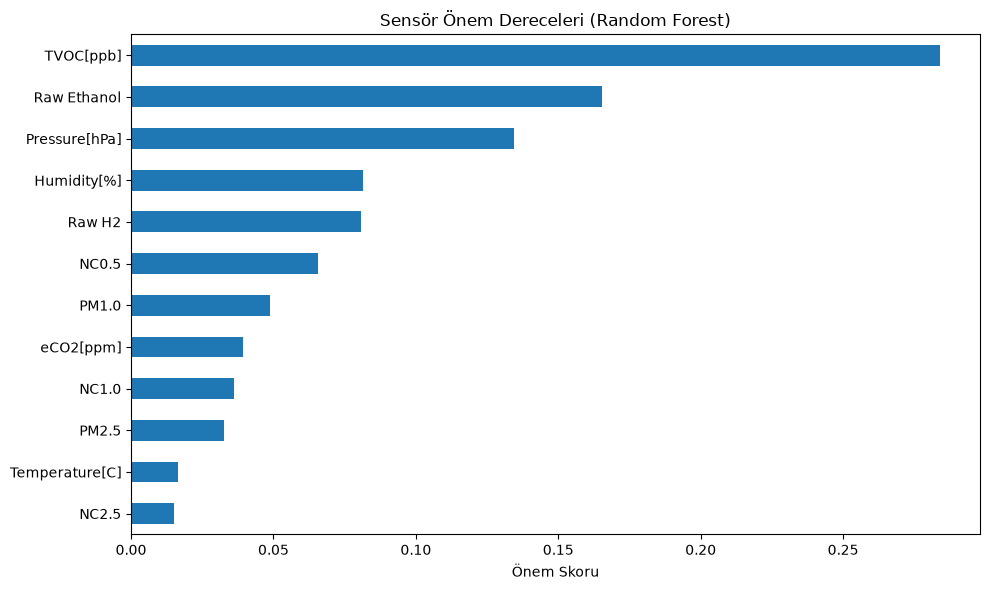

TVOC[ppb]         0.284
Raw Ethanol       0.165
Pressure[hPa]     0.134
Humidity[%]       0.081
Raw H2            0.081
NC0.5             0.065
PM1.0             0.049
eCO2[ppm]         0.039
NC1.0             0.036
PM2.5             0.033
Temperature[C]    0.017
NC2.5             0.015
dtype: float64


In [9]:
en_iyi = arama.best_estimator_

onem = pd.Series(en_iyi.feature_importances_, index=X_egitim.columns).sort_values()
onem.plot(kind="barh", figsize=(10, 6))
plt.title("Sensör Önem Dereceleri (Random Forest)")
plt.xlabel("Önem Skoru")
plt.tight_layout()
plt.savefig("sensor_onem.png")
plt.show()
print(onem.sort_values(ascending=False).round(3))

GridSearch (scoring=recall, cv=3) sonucu en iyi Random Forest ayarları: **max_depth=4, n_estimators=50** (çapraz doğrulama recall = 0.9518). Sensör önem analizinde **TVOC[ppb]** en baskın özellik (0.284), ardından **Raw Ethanol** (0.165) ve **Pressure[hPa]** (0.134) geliyor. Yani yangını en erken uçucu organik bileşik ve gaz sensörleri haber veriyor; sıcaklık (0.017) en az etkili sensörlerden biri.

## Karar eşiğini doğrulama setinde seçme

Model 0–1 arası bir olasılık verir; varsayılan eşik 0.5'tir. Eşiği yükseltmek yanlış alarmı azaltır ama yangın kaçırma riskini artırır. Eşiği **yalnızca doğrulama setine** bakarak seçiyoruz. Kural: recall ≥ 0.99 kalan en yüksek eşik (0.95 şartına güvenlik payı).

In [10]:
from sklearn.metrics import confusion_matrix

olasilik_dog = en_iyi.predict_proba(X_dogrulama)[:, 1]
uygun_esikler = []
for esik in [0.5, 0.6, 0.7, 0.8, 0.9]:
    tahmin = (olasilik_dog >= esik).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dogrulama, tahmin).ravel()
    print(f"Eşik {esik}: recall={tp/(tp+fn):.4f}  yanlış alarm oranı={fp/(fp+tn):.4f}")
    if tp / (tp + fn) >= 0.99:
        uygun_esikler.append(esik)

ESIK = max(uygun_esikler)
print("\nSeçilen eşik:", ESIK)

Eşik 0.5: recall=1.0000  yanlış alarm oranı=0.5409
Eşik 0.6: recall=1.0000  yanlış alarm oranı=0.4186
Eşik 0.7: recall=0.9999  yanlış alarm oranı=0.2071
Eşik 0.8: recall=0.9983  yanlış alarm oranı=0.0387
Eşik 0.9: recall=0.9889  yanlış alarm oranı=0.0000

Seçilen eşik: 0.8


## Test seti — ilk ve tek dokunuş

Bu hücre bir kez çalıştırıldı. Bundan sonra test setiyle deneme yapılmaz; yeni denemeler doğrulama setinde yapılır.

In [11]:
from sklearn.metrics import roc_auc_score

olasilik_test = en_iyi.predict_proba(X_test)[:, 1]
tahmin_test = (olasilik_test >= ESIK).astype(int)

print("TEST SETİ — eşik:", ESIK)
print("  Accuracy:", accuracy_score(y_test, tahmin_test))
print("  Precision:", precision_score(y_test, tahmin_test))
print("  Recall:", recall_score(y_test, tahmin_test))
print("  F1:", f1_score(y_test, tahmin_test))
print("  ROC-AUC:", roc_auc_score(y_test, olasilik_test))

cm = confusion_matrix(y_test, tahmin_test)
print(cm)
tn, fp, fn, tp = cm.ravel()
print("Yanlış alarm oranı:", fp / (fp + tn))

TEST SETİ — eşik: 0.8
  Accuracy: 0.9098386839163073
  Precision: 0.908486753480018
  Recall: 0.9892431058087229
  F1: 0.9471466691634287
  ROC-AUC: 0.9905058142427139
[[ 1277  1019]
 [  110 10116]]
Yanlış alarm oranı: 0.44381533101045295


### Test seti sonuçları (eşik = 0.8)

| Metrik             | Değer  |
|--------------------|--------|
| Accuracy           | 0.9098 |
| Precision          | 0.9085 |
| Recall             | 0.9892 |
| F1                 | 0.9471 |
| ROC-AUC            | 0.9905 |
| Yanlış alarm oranı | 0.4438 (2296 yangınsız satırın 1019'unda alarm) |

Recall 0.9892 ile 0.95 şartını sağlıyor: test setindeki 10226 gerçek yangın satırının yalnızca 110'u kaçırıldı. Ancak yanlış alarm oranı test setinde %44 çıktı; doğrulama setinde aynı eşikte bu oran %3.9'du. Yani sensör modeli tek başına, görmediği koşullarda çok yanlış alarm üretebiliyor. Bu, S2 (yanlış alarm) senaryosunun ve sistemdeki **kamera doğrulaması + operatör onayı (ŞÜPHELİ seviyesi)** tasarımının gerekçesidir: sensör tek başına karar vermez.

## Bölme yöntemi hakkında not

İlk denemede veriyi dosya sırasına göre böldük; test setine neredeyse yalnızca yangınsız kayıt oturumları düştü ve model çöktü (accuracy 0.06). İnceleme sonucunda veri setinin 5 ayrı kayıt oturumundan oluştuğunu (CNT sayacının sıfırlandığı noktalar) gördük. Bölmeyi her oturumun kendi içinde zamana göre yaptık (ilk %60 eğitim, %20 doğrulama, son %20 test). Karar eşiğini yalnızca doğrulama setinde seçtik; test setine tek kez dokunduk.

## Modeli dosyaya kaydetme

Seçilen model `models/sensor_model.joblib` olarak kaydedilir. Bu dosya GitHub'a yüklenmez (`.gitignore`); Drive'da `YanginProjesi/modeller` klasöründe durur. Web uygulaması modeli `src/sensor.py` üzerinden kullanır.

In [12]:
import joblib
# Notebook "notebooks" klasöründe çalışıyor; ".." bir üst klasör (proje kökü) demek
joblib.dump(en_iyi, "../models/sensor_model.joblib")
print("Kaydedildi. Eğitimde kullanılan sütun sırası:")
print(list(X_egitim.columns))

Kaydedildi. Eğitimde kullanılan sütun sırası:
['Temperature[C]', 'Humidity[%]', 'TVOC[ppb]', 'eCO2[ppm]', 'Raw H2', 'Raw Ethanol', 'Pressure[hPa]', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5']


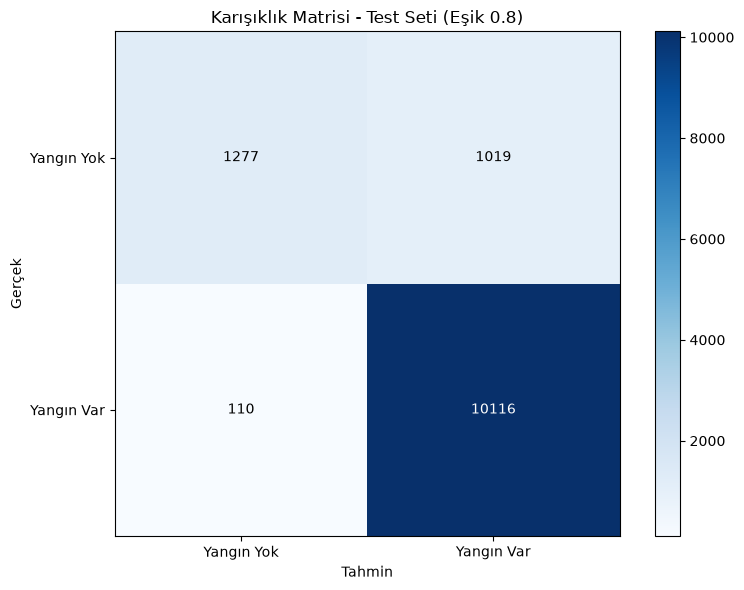

Kaydedildi: confusion_matrix.png


In [13]:
# Test setindeki karışıklık matrisi — yukarıda seçilen eşikle (ESIK) yapılan tahminler
# Not: test setine yeniden tahmin yaptırmıyoruz, "tek dokunuş" hücresindeki tahmin_test kullanılıyor
cm = confusion_matrix(y_test, tahmin_test)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax.set_title(f'Karışıklık Matrisi - Test Seti (Eşik {ESIK})')
plt.colorbar(im, ax=ax)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Yangın Yok', 'Yangın Var'])
ax.set_yticklabels(['Yangın Yok', 'Yangın Var'])
ax.set_ylabel('Gerçek')
ax.set_xlabel('Tahmin')

for i in range(2):
    for j in range(2):
        ax.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")

plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

print("Kaydedildi: confusion_matrix.png")